# Entregable 2: Programación y validación de algoritmos bioinspirados (CVRP)

Hugo André Meza Fierros - A00841695

Gil Brandon García Contreras - A01254164

Jesús Alejandro Pérez Granados - A01253993

Santiago Hernández Jiménez - A01662307

Luis Santiago Benvenuto Valerdi - A01286400

---

Este notebook continúa el Entregable 1 (`cvrp_entregable1.ipynb`) sobre la instancia `NAME _CVRP_10_manual.txt` (10 clientes, $Q=50$). Se reutilizan la lectura de la instancia, la matriz de costos, las funciones de evaluación y los métodos de referencia (modelo exacto con PuLP + CBC, vecino más cercano y Clarke & Wright + 2-opt), y se agregan dos metaheurísticas bioinspiradas:

1. **Algoritmo genético (AG)** con representación de *tour gigante* y decodificación óptima `Split` (Prins, 2004).
2. **Colonia de hormigas (ACO)**, variante *Ant System* elitista para el CVRP (Bullnheimer et al., 1999).

Para cada uno se calibran los hiperparámetros, se valida con 30 corridas independientes y se reportan función objetivo, número de rutas, espacio desperdiciado por ruta y el trazado de las rutas. Al final se comparan contra el modelo matemático y el algoritmo del Entregable 1. Las figuras se guardan en `Images/entregable2/` y las tablas LaTeX en `resultados/`.

In [1]:
import math
import time
import json
import random
from itertools import combinations, product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp

INSTANCIA = Path("NAME _CVRP_10_manual.txt")
IMG = Path("Images/entregable2"); IMG.mkdir(parents=True, exist_ok=True)
OUT = Path("resultados"); OUT.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})

## 1. Instancia, matriz de costos y funciones de evaluación (Entregable 1)

Mismo código del Entregable 1: lectura en formato TSPLIB/CVRPLIB, matriz de distancias euclidianas $c_{ij}$ y funciones para evaluar, resumir y graficar soluciones. Una solución es una lista de rutas; cada ruta es la secuencia de clientes (el depósito al inicio y al final está implícito).

- **Función objetivo**: $Z = \sum_{r}\sum_{(i,j)\in r} c_{ij}$.
- **Espacio desperdiciado** de la ruta $r$: $\displaystyle w_r = \frac{Q - \sum_{i\in r} q_i}{Q}\times 100\%$.

In [2]:
def leer_instancia(ruta):
    info, coords, demandas, depositos = {}, {}, {}, []
    seccion = None
    for linea in Path(ruta).read_text().splitlines():
        linea = linea.strip()
        if not linea or linea == "EOF":
            continue
        if linea.endswith("SECTION"):
            seccion = linea
            continue
        if seccion is None:
            clave, valor = [s.strip() for s in linea.split(":", 1)]
            info[clave] = valor
        elif seccion == "NODE_COORD_SECTION":
            i, x, y = linea.split()
            coords[int(i)] = (float(x), float(y))
        elif seccion == "DEMAND_SECTION":
            i, d = linea.split()
            demandas[int(i)] = int(d)
        elif seccion == "DEPOT_SECTION" and linea != "-1":
            depositos.append(int(linea))
    return info, coords, demandas, depositos[0]

info, coords, q, DEP = leer_instancia(INSTANCIA)
Q = int(info["CAPACITY"])
NODOS = sorted(coords)
CLIENTES = [i for i in NODOS if i != DEP]
demanda_total = sum(q.values())
K_MIN = math.ceil(demanda_total / Q)

X = np.array([coords[i] for i in NODOS])
D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
C = {i: {j: float(D[a, b]) for b, j in enumerate(NODOS)} for a, i in enumerate(NODOS)}
IDX = {v: a for a, v in enumerate(NODOS)}   # nodo -> fila/columna de D

print(info)
print(f"Depósito: {DEP} | Clientes: {len(CLIENTES)} | Q = {Q} | Demanda total = {demanda_total} | K_min = {K_MIN}")

{'NAME': 'CVRP_10', 'COMMENT': 'Instancia didactica con 10 clientes', 'TYPE': 'CVRP', 'DIMENSION': '11', 'EDGE_WEIGHT_TYPE': 'EUC_2D', 'CAPACITY': '50'}
Depósito: 1 | Clientes: 10 | Q = 50 | Demanda total = 146 | K_min = 3


In [3]:
def costo_ruta(ruta):
    camino = [DEP] + list(ruta) + [DEP]
    return sum(C[a][b] for a, b in zip(camino, camino[1:]))

def costo_total(rutas):
    return sum(costo_ruta(r) for r in rutas)

def es_factible(rutas):
    visitados = sorted(i for r in rutas for i in r)
    return visitados == sorted(CLIENTES) and all(sum(q[i] for i in r) <= Q for r in rutas)

def canonica(rutas):
    # Misma solución con orientación y orden fijos (c_ij es simétrica), para comparar métodos.
    rutas = [list(r) if r[0] <= r[-1] else list(r)[::-1] for r in rutas]
    return sorted(rutas, key=lambda r: r[0])

def resumen_rutas(rutas):
    filas = []
    for k, r in enumerate(rutas, 1):
        carga = sum(q[i] for i in r)
        filas.append({
            "ruta": f"R{k}",
            "secuencia": " - ".join(map(str, [DEP] + list(r) + [DEP])),
            "carga": carga,
            "costo": round(costo_ruta(r), 2),
            "desperdicio_%": round(100 * (Q - carga) / Q, 2),
        })
    df = pd.DataFrame(filas).set_index("ruta")
    total = sum(sum(q[i] for i in r) for r in rutas)
    df.loc["Total"] = ["", total, round(costo_total(rutas), 2), round(100 * (len(rutas) * Q - total) / (len(rutas) * Q), 2)]
    return df

COLORES = plt.cm.tab10.colors

def graficar_rutas(rutas, titulo, archivo):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for k, r in enumerate(rutas):
        camino = [DEP] + list(r) + [DEP]
        xs, ys = zip(*(coords[i] for i in camino))
        carga = sum(q[i] for i in r)
        ax.plot(xs, ys, "-", color=COLORES[k], lw=2,
                label=f"R{k+1}: carga {carga}/{Q}, costo {costo_ruta(r):.2f}")
        for a, b in zip(camino, camino[1:]):
            (x0, y0), (x1, y1) = coords[a], coords[b]
            ax.annotate("", xy=(x0 + 0.55 * (x1 - x0), y0 + 0.55 * (y1 - y0)), xytext=(x0, y0),
                        arrowprops=dict(arrowstyle="-|>", color=COLORES[k], lw=1.5))
    for i in CLIENTES:
        ax.scatter(*coords[i], s=90, c="white", edgecolors="k", zorder=3)
        ax.annotate(str(i), coords[i], ha="center", va="center", fontsize=7, zorder=4)
    ax.scatter(*coords[DEP], marker="s", s=170, c="tab:red", zorder=4)
    ax.annotate("1", coords[DEP], ha="center", va="center", fontsize=7, color="white", zorder=5)
    ax.set(xlabel="x", ylabel="y", title=f"{titulo}\nZ = {costo_total(rutas):.2f}, {len(rutas)} rutas",
           xlim=(10, 95), ylim=(15, 90))
    ax.grid(alpha=0.3); ax.set_aspect("equal")
    ax.legend(fontsize=7.5, loc="lower left")
    fig.tight_layout(); fig.savefig(IMG / archivo); plt.show()

def tabla_latex(df, archivo, caption, label, fmt="{:.2f}", col_index="", resize=False):
    # Escribe un DataFrame como tabla booktabs (sin depender de jinja2).
    cols = "l" + "r" * len(df.columns)
    filas = []
    for idx, fila in df.iterrows():
        celdas = [fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in fila]
        filas.append(" & ".join([str(idx)] + celdas) + r" \\")
    cuerpo = "\n".join(filas)
    encabezado = " & ".join([col_index] + [str(c) for c in df.columns]) + r" \\"
    tabular = (f"\\begin{{tabular}}{{{cols}}}\n\\toprule\n{encabezado}\n\\midrule\n"
               f"{cuerpo}\n\\bottomrule\n\\end{{tabular}}")
    if resize:
        tabular = f"\\resizebox{{\\textwidth}}{{!}}{{%\n{tabular}}}"
    tex = (f"\\begin{{table}}[H]\n\\centering\n\\caption{{{caption}}}\n\\label{{{label}}}\n"
           f"{tabular}\n\\end{{table}}\n")
    (OUT / archivo).write_text(tex)

def exportar_rutas(df, archivo, caption, label):
    df2 = df.copy()
    df2.columns = ["Secuencia", "Carga", "Costo", "Desperdicio (\\%)"]
    tabla_latex(df2, archivo, caption, label, col_index="Ruta")

## 2. Métodos de referencia del Entregable 1

Se vuelven a ejecutar aquí para tener los tiempos medidos en la misma sesión que las metaheurísticas: modelo exacto (PLEM de dos índices con restricciones MTZ de carga, PuLP + CBC) con flota libre y con flota fija $K=3$, vecino más cercano y Clarke & Wright + 2-opt.

In [4]:
def vecino_mas_cercano():
    pendientes = set(CLIENTES)
    rutas = []
    while pendientes:
        ruta, carga, actual = [], 0, DEP
        while True:
            factibles = [j for j in pendientes if carga + q[j] <= Q]
            if not factibles:
                break
            j = min(factibles, key=lambda j: C[actual][j])
            ruta.append(j); carga += q[j]; pendientes.remove(j); actual = j
        rutas.append(ruta)
    return rutas

def elegir_solver():
    # CBC (el de PuLP) si su binario corre en esta máquina; si no (p. ej. Apple Silicon sin Rosetta), HiGHS.
    try:
        prueba = pulp.LpProblem("prueba", pulp.LpMinimize)
        prueba += pulp.LpVariable("z", 0, 1)
        prueba.solve(pulp.PULP_CBC_CMD(msg=False))
        return pulp.PULP_CBC_CMD
    except Exception:
        return pulp.HiGHS

SOLVER = elegir_solver()
print("Solver MILP:", SOLVER.__name__)

def resolver_cvrp_exacto(K_fijo=None, tiempo_limite=600):
    arcos = [(i, j) for i in NODOS for j in NODOS if i != j]
    prob = pulp.LpProblem("CVRP_10", pulp.LpMinimize)
    x = pulp.LpVariable.dicts("x", arcos, cat="Binary")
    u = {i: pulp.LpVariable(f"u_{i}", lowBound=q[i], upBound=Q) for i in CLIENTES}

    prob += pulp.lpSum(C[i][j] * x[i, j] for i, j in arcos), "Distancia_total"
    for j in CLIENTES:
        prob += pulp.lpSum(x[i, j] for i in NODOS if i != j) == 1, f"entra_{j}"
    for i in CLIENTES:
        prob += pulp.lpSum(x[i, j] for j in NODOS if j != i) == 1, f"sale_{i}"
    salen = pulp.lpSum(x[DEP, j] for j in CLIENTES)
    prob += salen == pulp.lpSum(x[i, DEP] for i in CLIENTES), "flujo_deposito"
    if K_fijo is None:
        prob += salen >= K_MIN, "min_vehiculos"
    else:
        prob += salen == K_fijo, "flota_fija"
    for i in CLIENTES:
        for j in CLIENTES:
            if i != j:
                prob += u[j] >= u[i] + q[j] - Q * (1 - x[i, j]), f"mtz_{i}_{j}"

    prob.solve(SOLVER(msg=False, timeLimit=tiempo_limite))

    sucesor = {i: j for (i, j) in arcos if x[i, j].value() > 0.5 and i != DEP}
    rutas = []
    for j in CLIENTES:
        if x[DEP, j].value() > 0.5:
            ruta, actual = [], j
            while actual != DEP:
                ruta.append(actual); actual = sucesor[actual]
            rutas.append(ruta)
    return rutas

def clarke_wright():
    rutas = {i: [i] for i in CLIENTES}
    ruta_de = {i: i for i in CLIENTES}
    carga = {i: q[i] for i in CLIENTES}
    ahorros = sorted(((C[DEP][i] + C[DEP][j] - C[i][j], i, j) for i, j in combinations(CLIENTES, 2)),
                     reverse=True)
    for s, i, j in ahorros:
        ri, rj = ruta_de[i], ruta_de[j]
        if s <= 0 or ri == rj or carga[ri] + carga[rj] > Q:
            continue
        A, B = rutas[ri], rutas[rj]
        if A[-1] == i and B[0] == j:
            nueva = A + B
        elif A[0] == i and B[-1] == j:
            nueva = B + A
        elif A[0] == i and B[0] == j:
            nueva = A[::-1] + B
        elif A[-1] == i and B[-1] == j:
            nueva = A + B[::-1]
        else:
            continue
        rutas[ri] = nueva
        carga[ri] += carga.pop(rj)
        del rutas[rj]
        for k in B:
            ruta_de[k] = ri
    return list(rutas.values())

def dos_opt(ruta):
    camino = [DEP] + list(ruta) + [DEP]
    mejora = True
    while mejora:
        mejora = False
        for a in range(1, len(camino) - 2):
            for b in range(a + 1, len(camino) - 1):
                delta = (C[camino[a - 1]][camino[b]] + C[camino[a]][camino[b + 1]]
                         - C[camino[a - 1]][camino[a]] - C[camino[b]][camino[b + 1]])
                if delta < -1e-9:
                    camino[a:b + 1] = camino[a:b + 1][::-1]
                    mejora = True
    return camino[1:-1]

def algoritmo_cw_2opt():
    return [dos_opt(r) for r in clarke_wright()]

def cronometrar(f, repeticiones):
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        res = f()
    return res, (time.perf_counter() - t0) / repeticiones

rutas_exacto, t_exacto = cronometrar(resolver_cvrp_exacto, 5)
rutas_k3, t_k3 = cronometrar(lambda: resolver_cvrp_exacto(K_fijo=K_MIN), 5)
rutas_nn, t_nn = cronometrar(vecino_mas_cercano, 1000)
rutas_cw, t_cw = cronometrar(algoritmo_cw_2opt, 1000)
Z_OPT = costo_total(rutas_exacto)

for nombre, r, t in [("Exacto", rutas_exacto, t_exacto), ("Exacto K=3", rutas_k3, t_k3),
                     ("Vecino más cercano", rutas_nn, t_nn), ("C&W + 2-opt", rutas_cw, t_cw)]:
    assert es_factible(r)
    print(f"{nombre:20s} Z = {costo_total(r):8.2f} | rutas = {len(r)} | t = {t:.2e} s")

Solver MILP: HiGHS


Exacto               Z =   318.99 | rutas = 4 | t = 7.98e-01 s
Exacto K=3           Z =   339.16 | rutas = 3 | t = 1.68e+00 s
Vecino más cercano   Z =   358.35 | rutas = 3 | t = 7.86e-06 s
C&W + 2-opt          Z =   339.25 | rutas = 4 | t = 1.54e-05 s


## 3. Algoritmo genético (AG)

### 3.1 Diseño

- **Cromosoma**: permutación de los 10 clientes (*tour gigante*, sin delimitadores de ruta).
- **Decodificación `Split`** (Prins, 2004): dada la permutación $\pi$, se construye un grafo auxiliar acíclico donde el arco $(i, j)$ representa la ruta $1 \to \pi_{i+1} \to \dots \to \pi_j \to 1$, que existe sólo si su carga no excede $Q$. El camino más corto (programación dinámica de Bellman, $O(n^2)$) da la partición **óptima** de esa permutación en rutas factibles. Así todo cromosoma es factible y el número de rutas lo decide el propio algoritmo.
- **Aptitud**: $f(\pi) = Z(\text{Split}(\pi))$, a minimizar.
- **Selección**: torneo de tamaño $k$.
- **Cruce**: *Order Crossover* (OX), que conserva el orden relativo de los clientes y siempre produce permutaciones válidas.
- **Mutación**: con probabilidad $p_m$, intercambio de dos genes o inversión de un segmento (50/50).
- **Elitismo**: los $e$ mejores individuos pasan intactos a la siguiente generación.
- **Paro**: número fijo de generaciones.

In [5]:
def split(perm):
    # Partición óptima de un tour gigante en rutas factibles (camino más corto en un DAG).
    n = len(perm)
    V = [0.0] + [math.inf] * n          # V[j]: costo mínimo para servir perm[:j]
    P = [0] * (n + 1)                   # predecesor en el camino más corto
    for i in range(n):
        carga, dist = 0, 0.0
        for j in range(i, n):
            carga += q[perm[j]]
            if carga > Q:
                break
            dist = C[DEP][perm[i]] if j == i else dist + C[perm[j - 1]][perm[j]]
            costo = V[i] + dist + C[perm[j]][DEP]
            if costo < V[j + 1] - 1e-12:
                V[j + 1], P[j + 1] = costo, i
    rutas, j = [], n
    while j > 0:
        rutas.append(list(perm[P[j]:j])); j = P[j]
    return V[n], rutas[::-1]

def cruce_ox(p1, p2, rng):
    n = len(p1)
    a, b = sorted(rng.sample(range(n), 2))
    hijo = [None] * n
    hijo[a:b + 1] = p1[a:b + 1]
    usados = set(hijo[a:b + 1])
    resto = [g for g in p2[b + 1:] + p2[:b + 1] if g not in usados]
    for k, g in zip(list(range(b + 1, n)) + list(range(a)), resto):
        hijo[k] = g
    return hijo

def mutacion(p, rng):
    p = p[:]
    a, b = sorted(rng.sample(range(len(p)), 2))
    if rng.random() < 0.5:
        p[a], p[b] = p[b], p[a]                 # intercambio
    else:
        p[a:b + 1] = p[a:b + 1][::-1]           # inversión
    return p

def algoritmo_genetico(tam_pob=50, generaciones=150, p_cruce=0.9, p_mutacion=0.2,
                       k_torneo=3, elite=2, semilla=None):
    rng = random.Random(semilla)
    pob = [rng.sample(CLIENTES, len(CLIENTES)) for _ in range(tam_pob)]
    apt = [split(p)[0] for p in pob]
    hist_mejor, hist_prom = [min(apt)], [float(np.mean(apt))]

    def torneo():
        return pob[min(rng.sample(range(tam_pob), k_torneo), key=apt.__getitem__)]

    for _ in range(generaciones):
        orden = sorted(range(tam_pob), key=apt.__getitem__)
        nueva = [pob[i] for i in orden[:elite]]
        while len(nueva) < tam_pob:
            p1, p2 = torneo(), torneo()
            hijo = cruce_ox(p1, p2, rng) if rng.random() < p_cruce else p1[:]
            if rng.random() < p_mutacion:
                hijo = mutacion(hijo, rng)
            nueva.append(hijo)
        pob = nueva
        apt = [split(p)[0] for p in pob]
        hist_mejor.append(min(min(apt), hist_mejor[-1]))
        hist_prom.append(float(np.mean(apt)))

    mejor = pob[int(np.argmin(apt))]
    Z, rutas = split(mejor)
    return {"rutas": rutas, "Z": Z, "cromosoma": mejor,
            "hist_mejor": hist_mejor, "hist_prom": hist_prom}

res = algoritmo_genetico(semilla=0)
print(f"Prueba AG: Z = {res['Z']:.2f}, rutas = {res['rutas']}")
print("Ejemplo de decodificación Split del mejor cromosoma:", res["cromosoma"], "->", res["rutas"])

Prueba AG: Z = 318.99, rutas = [[3, 2, 6], [10], [4, 5, 11], [7, 8, 9]]
Ejemplo de decodificación Split del mejor cromosoma: [3, 2, 6, 10, 4, 5, 11, 7, 8, 9] -> [[3, 2, 6], [10], [4, 5, 11], [7, 8, 9]]


## 4. Colonia de hormigas (ACO)

### 4.1 Diseño

Variante *Ant System* elitista para el CVRP (Bullnheimer, Hartl y Strauss, 1999):

- Cada una de las $m$ hormigas construye una solución completa. Sale del depósito y, estando en el nodo $i$, elige el siguiente cliente $j$ entre los **pendientes cuya demanda cabe** en la capacidad restante ($\Omega_i$) con probabilidad
$$p_{ij} = \frac{\tau_{ij}^{\alpha}\,\eta_{ij}^{\beta}}{\sum_{l\in\Omega_i}\tau_{il}^{\alpha}\,\eta_{il}^{\beta}}, \qquad \eta_{ij} = \frac{1}{c_{ij}}.$$
  Si $\Omega_i=\emptyset$, regresa al depósito y abre una nueva ruta. Así toda solución es factible.
- **Evaporación**: $\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij}$.
- **Depósito**: cada hormiga $k$ deposita $1/Z_k$ en los arcos que usó, y la mejor solución global deposita $e/Z^{\text{best}}$ adicional (hormigas elitistas). La feromona es simétrica.
- **Inicialización**: $\tau_0 = m / Z_{\text{NN}}$ (Dorigo y Stützle, 2004), con $Z_{\text{NN}}$ el costo del vecino más cercano.
- **Paro**: número fijo de iteraciones.

In [6]:
def colonia_hormigas(m=10, iteraciones=150, alpha=1.0, beta=2.0, rho=0.1, e=5, semilla=None):
    rng = np.random.default_rng(semilla)
    n = len(NODOS)
    eta = 1.0 / (D + np.eye(n))                      # visibilidad (la diagonal no se usa)
    tau = np.full((n, n), m / costo_total(vecino_mas_cercano()))
    mejor, Z_mejor = None, math.inf
    hist_mejor, hist_prom = [], []

    def construir():
        pendientes, rutas = set(CLIENTES), []
        while pendientes:
            ruta, carga, i = [], 0, DEP
            while True:
                omega = [j for j in pendientes if carga + q[j] <= Q]
                if not omega:
                    break
                cols = [IDX[j] for j in omega]
                w = tau[IDX[i], cols] ** alpha * eta[IDX[i], cols] ** beta
                j = omega[rng.choice(len(omega), p=w / w.sum())]
                ruta.append(j); carga += q[j]; pendientes.remove(j); i = j
            rutas.append(ruta)
        return rutas

    def depositar(rutas, cantidad):
        for r in rutas:
            camino = [IDX[DEP]] + [IDX[v] for v in r] + [IDX[DEP]]
            for a, b in zip(camino, camino[1:]):
                tau[a, b] += cantidad; tau[b, a] += cantidad

    for _ in range(iteraciones):
        soluciones = [construir() for _ in range(m)]
        costos = [costo_total(s) for s in soluciones]
        k = int(np.argmin(costos))
        if costos[k] < Z_mejor:
            mejor, Z_mejor = soluciones[k], costos[k]
        tau *= (1 - rho)
        for s, z in zip(soluciones, costos):
            depositar(s, 1.0 / z)
        depositar(mejor, e / Z_mejor)
        hist_mejor.append(Z_mejor); hist_prom.append(float(np.mean(costos)))

    return {"rutas": mejor, "Z": Z_mejor, "hist_mejor": hist_mejor, "hist_prom": hist_prom, "tau": tau}

res = colonia_hormigas(semilla=0)
print(f"Prueba ACO: Z = {res['Z']:.2f}, rutas = {res['rutas']}")

Prueba ACO: Z = 318.99, rutas = [[7, 8, 9], [4, 5, 11], [6, 2, 3], [10]]


## 5. Calibración de hiperparámetros

Con 10 clientes ambos algoritmos llegan al óptimo con presupuestos generosos, así que la calibración se hace con un presupuesto **reducido** para que las diferencias se noten. Para cada combinación se ejecutan 20 semillas y se mide:

- **Tasa de éxito**: % de corridas que alcanzan $Z^* = 318.99$.
- **$\bar Z$**: costo promedio final.
- **Evaluaciones hasta el óptimo**: número promedio de soluciones evaluadas antes de alcanzar $Z^*$ (sólo corridas exitosas). Es una medida de esfuerzo comparable entre configuraciones con distinto tamaño de población.

Para el AG se varían el tamaño de población y la probabilidad de mutación (60 generaciones, $p_c=0.9$, $k=3$, $e=2$). Para ACO se varían $\beta$ y $\rho$ (40 iteraciones, $m=10$, $\alpha=1$, $e=5$).

In [7]:
SEMILLAS_CAL = range(20)

def primera_vez(hist, objetivo=None, tol=1e-6):
    # Índice (generación/iteración) en que el mejor histórico alcanza el objetivo; None si nunca.
    objetivo = Z_OPT if objetivo is None else objetivo
    return next((g for g, v in enumerate(hist) if v <= objetivo + tol), None)

def calibrar(algoritmo, rejilla, fijos, evals_por_iter, semillas=SEMILLAS_CAL):
    filas = []
    nombres = list(rejilla)
    for valores in product(*rejilla.values()):
        hp = dict(zip(nombres, valores))
        Zs, evals = [], []
        for s in semillas:
            r = algoritmo(**fijos, **hp, semilla=s)
            Zs.append(r["Z"])
            g = primera_vez(r["hist_mejor"])
            if g is not None:
                evals.append(evals_por_iter({**fijos, **hp}) * (g + 1))
        filas.append({**hp, "exito_%": 100 * np.mean(np.isclose(Zs, Z_OPT)),
                      "Z_prom": np.mean(Zs), "Z_std": np.std(Zs),
                      "evals_optimo": np.mean(evals) if evals else np.nan})
    return pd.DataFrame(filas)

t0 = time.perf_counter()
cal_ag = calibrar(algoritmo_genetico,
                  {"tam_pob": [20, 50, 100], "p_mutacion": [0.05, 0.2, 0.5]},
                  {"generaciones": 60, "p_cruce": 0.9, "k_torneo": 3, "elite": 2},
                  evals_por_iter=lambda hp: hp["tam_pob"])
print(f"Calibración AG: {time.perf_counter() - t0:.1f} s")
cal_ag.round(2)

Calibración AG: 6.5 s


,tam_pob,p_mutacion,exito_%,Z_prom,Z_std,evals_optimo
0,20,0.05,50.0,326.11,7.37,520.00
1,20,0.20,65.0,323.94,6.88,387.69
2,20,0.50,95.0,319.59,2.61,514.74
3,50,0.05,85.0,320.97,4.71,732.35
4,50,0.20,90.0,320.47,4.55,638.89
5,50,0.50,100.0,318.99,0.00,685.00
6,100,0.05,95.0,319.59,2.61,868.42
7,100,0.20,90.0,320.47,4.55,844.44
8,100,0.50,100.0,318.99,0.00,1105.00


In [8]:
t0 = time.perf_counter()
cal_aco = calibrar(colonia_hormigas,
                   {"beta": [1, 2, 3, 5], "rho": [0.05, 0.1, 0.3, 0.5]},
                   {"m": 10, "iteraciones": 40, "alpha": 1.0, "e": 5},
                   evals_por_iter=lambda hp: hp["m"])
print(f"Calibración ACO: {time.perf_counter() - t0:.1f} s")
cal_aco.round(2)

Calibración ACO: 19.1 s


,beta,rho,exito_%,Z_prom,Z_std,evals_optimo
0,1,0.05,90.0,320.27,3.95,236.11
1,1,0.10,95.0,319.66,2.93,216.32
2,1,0.30,75.0,323.30,7.73,168.67
3,1,0.50,85.0,322.02,7.20,190.00
4,2,0.05,90.0,320.16,3.54,207.78
5,2,0.10,90.0,320.17,3.61,216.11
6,2,0.30,75.0,322.54,6.37,148.67
7,2,0.50,65.0,324.27,7.51,187.69
8,3,0.05,40.0,327.17,6.69,222.50
9,3,0.10,35.0,328.38,7.11,232.86


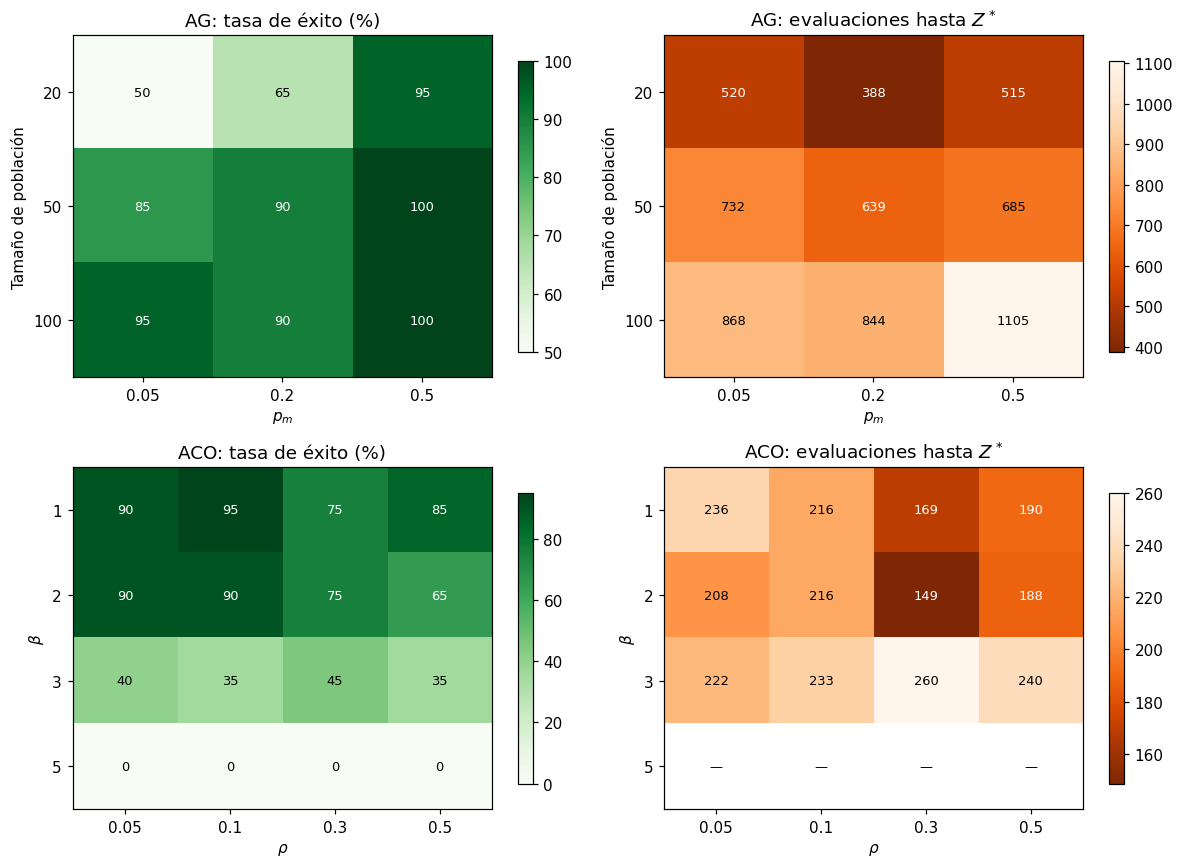

In [9]:
def mapa_calor(ax, df, fila, col, valor, titulo, fmt, cmap):
    tabla = df.pivot(index=fila, columns=col, values=valor)
    im = ax.imshow(tabla.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(tabla.columns)), tabla.columns)
    ax.set_yticks(range(len(tabla.index)), tabla.index)
    for a in range(tabla.shape[0]):
        for b in range(tabla.shape[1]):
            v = tabla.values[a, b]
            oscuro = not np.isnan(v) and np.mean(im.cmap(im.norm(v))[:3]) < 0.5
            ax.text(b, a, "—" if np.isnan(v) else fmt.format(v), ha="center", va="center", fontsize=8.5,
                    color="white" if oscuro else "black")
    ax.set(xlabel=col, ylabel=fila, title=titulo)
    plt.colorbar(im, ax=ax, shrink=0.85)

fig, axs = plt.subplots(2, 2, figsize=(11, 8))
mapa_calor(axs[0, 0], cal_ag, "tam_pob", "p_mutacion", "exito_%", "AG: tasa de éxito (%)", "{:.0f}", "Greens")
mapa_calor(axs[0, 1], cal_ag, "tam_pob", "p_mutacion", "evals_optimo", "AG: evaluaciones hasta $Z^*$", "{:.0f}", "Oranges_r")
mapa_calor(axs[1, 0], cal_aco, "beta", "rho", "exito_%", r"ACO: tasa de éxito (%)", "{:.0f}", "Greens")
mapa_calor(axs[1, 1], cal_aco, "beta", "rho", "evals_optimo", r"ACO: evaluaciones hasta $Z^*$", "{:.0f}", "Oranges_r")
axs[1, 0].set(xlabel=r"$\rho$", ylabel=r"$\beta$"); axs[1, 1].set(xlabel=r"$\rho$", ylabel=r"$\beta$")
axs[0, 0].set(xlabel="$p_m$", ylabel="Tamaño de población"); axs[0, 1].set(xlabel="$p_m$", ylabel="Tamaño de población")
fig.tight_layout(); fig.savefig(IMG / "calibracion.png"); plt.show()

In [10]:
# Hiperparámetros elegidos a partir de la calibración (ver discusión en el reporte).
HP_AG = {"tam_pob": 50, "generaciones": 150, "p_cruce": 0.9, "p_mutacion": 0.5, "k_torneo": 3, "elite": 2}
HP_ACO = {"m": 10, "iteraciones": 150, "alpha": 1.0, "beta": 1.0, "rho": 0.1, "e": 5}

## 6. Validación: 30 corridas independientes

Con los hiperparámetros elegidos, cada algoritmo se ejecuta con 30 semillas distintas. Se reporta la mejor solución encontrada y la estadística de las 30 corridas (mejor, promedio, desviación estándar, peor, tasa de éxito y tiempo promedio por corrida).

In [11]:
N_CORRIDAS = 30

def validar(algoritmo, hp):
    corridas = []
    for s in range(N_CORRIDAS):
        t0 = time.perf_counter()
        r = algoritmo(**hp, semilla=s)
        r["tiempo"] = time.perf_counter() - t0
        r["iter_optimo"] = primera_vez(r["hist_mejor"])
        assert es_factible(r["rutas"])
        corridas.append(r)
    return corridas

corr_ag = validar(algoritmo_genetico, HP_AG)
corr_aco = validar(colonia_hormigas, HP_ACO)

def estadisticas(corridas):
    Z = np.array([r["Z"] for r in corridas])
    it = [r["iter_optimo"] for r in corridas if r["iter_optimo"] is not None]
    return {"Mejor $Z$": Z.min(), "$\\bar Z$": Z.mean(), "Desv. est.": Z.std(), "Peor $Z$": Z.max(),
            "Éxito (\\%)": 100 * np.mean(np.isclose(Z, Z_OPT)),
            "Iter. al óptimo": np.mean(it) if it else np.nan,
            "Tiempo prom. (s)": np.mean([r["tiempo"] for r in corridas])}

df_stats = pd.DataFrame({"AG": estadisticas(corr_ag), "ACO": estadisticas(corr_aco)}).T
df_stats

,Mejor $Z$,$\bar Z$,Desv. est.,Peor $Z$,Éxito (\%),Iter. al óptimo,Tiempo prom. (s)
AG,318.989487,318.989487,5.684342e-14,318.989487,100.0,11.466667,0.082076
ACO,318.989487,318.989487,0.000000e+00,318.989487,100.0,23.200000,0.218885


### 6.1 Resultados del algoritmo genético

In [12]:
mejor_ag = min(corr_ag, key=lambda r: r["Z"])
rutas_ag = canonica(mejor_ag["rutas"])
df_ag = resumen_rutas(rutas_ag)
df_ag

,secuencia,carga,costo,desperdicio_%
ruta,,,,
R1,1 - 3 - 2 - 6 - 1,44,101.19,12.0
R2,1 - 4 - 5 - 11 - 1,42,86.18,16.0
R3,1 - 7 - 8 - 9 - 1,47,109.26,6.0
R4,1 - 10 - 1,13,22.36,74.0
Total,,146,318.99,27.0


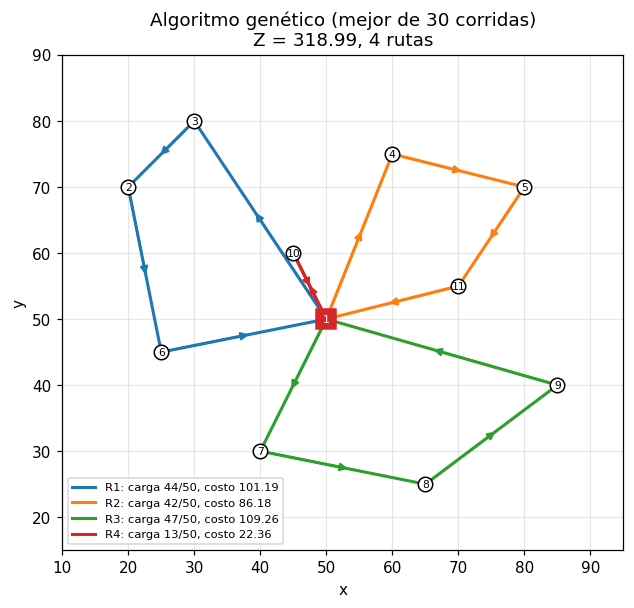

In [13]:
graficar_rutas(rutas_ag, "Algoritmo genético (mejor de 30 corridas)", "rutas_ag.png")

### 6.2 Resultados de la colonia de hormigas

In [14]:
mejor_aco = min(corr_aco, key=lambda r: r["Z"])
rutas_aco = canonica(mejor_aco["rutas"])
df_aco = resumen_rutas(rutas_aco)
df_aco

,secuencia,carga,costo,desperdicio_%
ruta,,,,
R1,1 - 3 - 2 - 6 - 1,44,101.19,12.0
R2,1 - 4 - 5 - 11 - 1,42,86.18,16.0
R3,1 - 7 - 8 - 9 - 1,47,109.26,6.0
R4,1 - 10 - 1,13,22.36,74.0
Total,,146,318.99,27.0


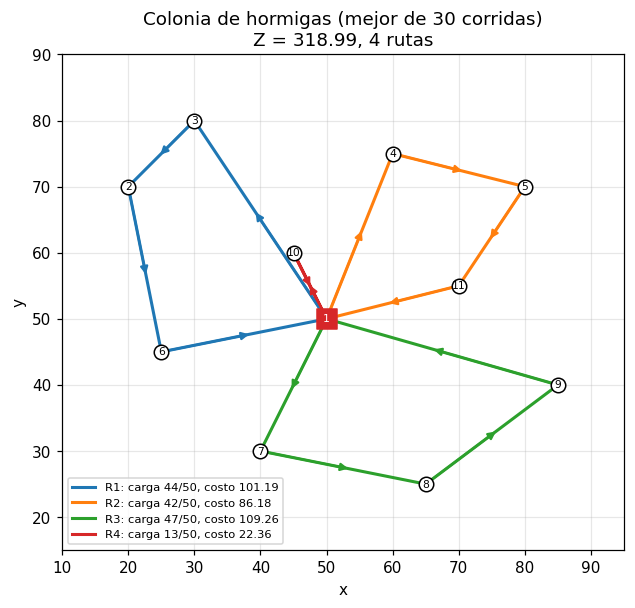

In [15]:
graficar_rutas(rutas_aco, "Colonia de hormigas (mejor de 30 corridas)", "rutas_aco.png")

### 6.3 Convergencia y distribución de resultados

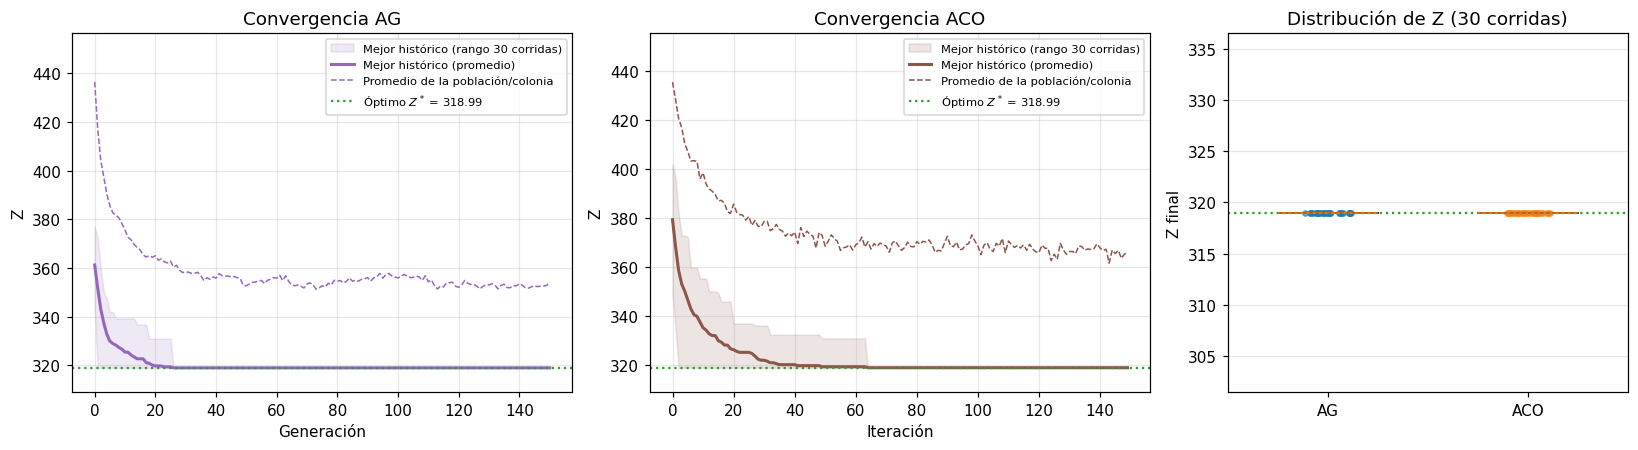

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for ax, corridas, nombre, color, eje in [(axs[0], corr_ag, "AG", "tab:purple", "Generación"),
                                         (axs[1], corr_aco, "ACO", "tab:brown", "Iteración")]:
    H = np.array([r["hist_mejor"] for r in corridas])
    P = np.array([r["hist_prom"] for r in corridas])
    g = np.arange(H.shape[1])
    ax.fill_between(g, H.min(0), H.max(0), color=color, alpha=0.15, label="Mejor histórico (rango 30 corridas)")
    ax.plot(g, H.mean(0), color=color, lw=2, label="Mejor histórico (promedio)")
    ax.plot(g, P.mean(0), color=color, lw=1, ls="--", label="Promedio de la población/colonia")
    ax.axhline(Z_OPT, color="tab:green", ls=":", lw=1.5, label=f"Óptimo $Z^*$ = {Z_OPT:.2f}")
    ax.set(xlabel=eje, ylabel="Z", title=f"Convergencia {nombre}", ylim=(Z_OPT - 10, P.mean(0).max() + 20))
    ax.grid(alpha=0.3); ax.legend(fontsize=7.5)

datos = [[r["Z"] for r in corr_ag], [r["Z"] for r in corr_aco]]
axs[2].boxplot(datos, tick_labels=["AG", "ACO"], widths=0.5)
for k, d in enumerate(datos, 1):
    axs[2].scatter(np.full(len(d), k) + np.random.default_rng(k).uniform(-0.12, 0.12, len(d)), d, s=12, alpha=0.6)
axs[2].axhline(Z_OPT, color="tab:green", ls=":", lw=1.5)
axs[2].set(ylabel="Z final", title=f"Distribución de Z ({N_CORRIDAS} corridas)")
axs[2].grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(IMG / "convergencia.png"); plt.show()

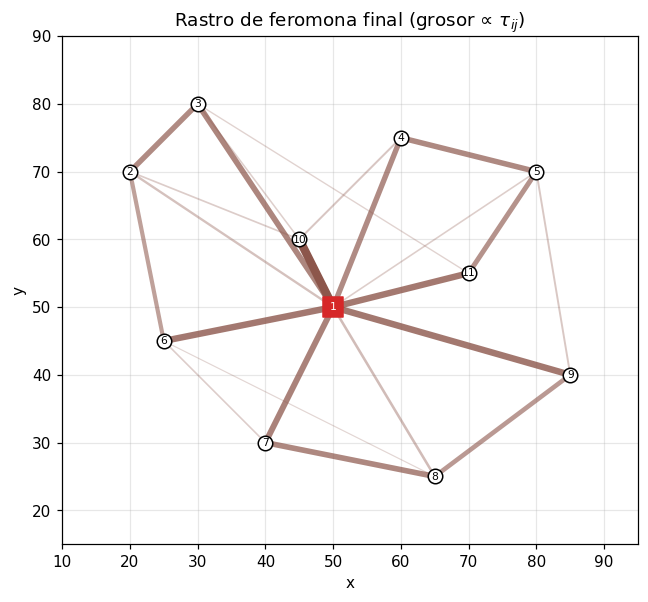

In [17]:
# Feromona final de la mejor corrida de ACO: los arcos reforzados coinciden con la mejor solución.
tau = mejor_aco["tau"]
fig, ax = plt.subplots(figsize=(6, 5.5))
tmax = tau.max()
for a in range(len(NODOS)):
    for b in range(a + 1, len(NODOS)):
        w = tau[a, b] / tmax
        if w > 0.05:
            (x0, y0), (x1, y1) = coords[NODOS[a]], coords[NODOS[b]]
            ax.plot([x0, x1], [y0, y1], color="tab:brown", lw=0.5 + 5 * w, alpha=0.2 + 0.8 * w)
for i in CLIENTES:
    ax.scatter(*coords[i], s=90, c="white", edgecolors="k", zorder=3)
    ax.annotate(str(i), coords[i], ha="center", va="center", fontsize=7, zorder=4)
ax.scatter(*coords[DEP], marker="s", s=170, c="tab:red", zorder=4)
ax.annotate("1", coords[DEP], ha="center", va="center", fontsize=7, color="white", zorder=5)
ax.set(xlabel="x", ylabel="y", title="Rastro de feromona final (grosor ∝ $\\tau_{ij}$)", xlim=(10, 95), ylim=(15, 90))
ax.grid(alpha=0.3); ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(IMG / "feromona.png"); plt.show()

## 7. Comparación con el modelo matemático y el algoritmo del Entregable 1

$$\text{GAP}_{\text{costo}} = \frac{Z_{\text{método}} - Z^*}{Z^*}\times 100\%.$$

Para AG y ACO se reporta la mejor solución de las 30 corridas, el GAP del costo promedio $\bar Z$ y el tiempo promedio por corrida.

In [18]:
def fila(nombre, rutas, t, Z_prom=None):
    Z = costo_total(rutas)
    carga = sum(q[i] for r in rutas for i in r)
    Z_prom = Z if Z_prom is None else Z_prom
    return {"Método": nombre, "Costo Z": round(Z, 2), "Rutas": len(rutas),
            "Desp. prom. %": round(100 * (len(rutas) * Q - carga) / (len(rutas) * Q), 2),
            "Tiempo (s)": t, "GAP mejor %": round(100 * (Z - Z_OPT) / Z_OPT, 2),
            "GAP prom. %": round(100 * (Z_prom - Z_OPT) / Z_OPT, 2),
            "Aceleración (×)": round(t_exacto / t, 1)}

df_comp = pd.DataFrame([
    fila("Exacto (PuLP)", rutas_exacto, t_exacto),
    fila("Exacto, flota fija K=3", rutas_k3, t_k3),
    fila("Vecino más cercano (E1)", rutas_nn, t_nn),
    fila("Clarke & Wright + 2-opt (E1)", rutas_cw, t_cw),
    fila("Algoritmo genético", rutas_ag, df_stats.loc["AG", "Tiempo prom. (s)"], df_stats.loc["AG", "$\\bar Z$"]),
    fila("Colonia de hormigas", rutas_aco, df_stats.loc["ACO", "Tiempo prom. (s)"], df_stats.loc["ACO", "$\\bar Z$"]),
]).set_index("Método")
pd.options.display.float_format = "{:.6g}".format
print("¿AG y ACO encuentran exactamente las mismas rutas que el modelo exacto?",
      canonica(rutas_exacto) == rutas_ag == rutas_aco)
df_comp

¿AG y ACO encuentran exactamente las mismas rutas que el modelo exacto? True


,Costo Z,Rutas,Desp. prom. %,Tiempo (s),GAP mejor %,GAP prom. %,Aceleración (×)
Método,,,,,,,
Exacto (PuLP),318.99,4,27,0.79831,0,0,1
"Exacto, flota fija K=3",339.16,3,2.67,1.6838,6.32,6.32,0.5
Vecino más cercano (E1),358.35,3,2.67,7.8565e-06,12.34,12.34,101611
Clarke & Wright + 2-opt (E1),339.25,4,27,1.53831e-05,6.35,6.35,51895.2
Algoritmo genético,318.99,4,27,0.0820756,0,0,9.7
Colonia de hormigas,318.99,4,27,0.218885,0,0,3.6


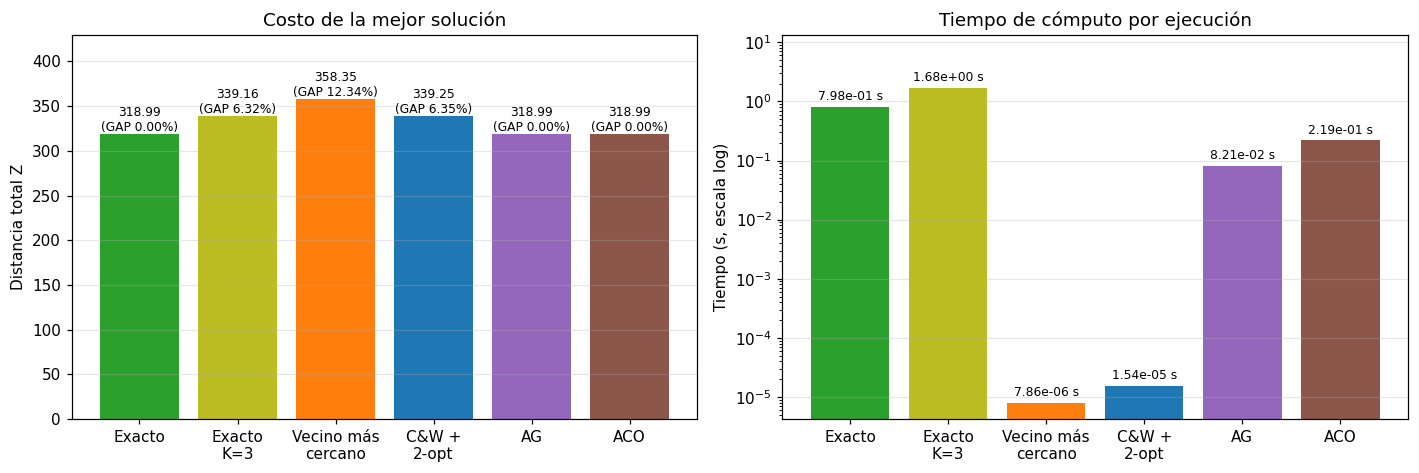

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
nombres = ["Exacto", "Exacto\nK=3", "Vecino más\ncercano", "C&W +\n2-opt", "AG", "ACO"]
colores = ["tab:green", "tab:olive", "tab:orange", "tab:blue", "tab:purple", "tab:brown"]
axs[0].bar(nombres, df_comp["Costo Z"], color=colores)
for k, (z, g) in enumerate(zip(df_comp["Costo Z"], df_comp["GAP mejor %"])):
    axs[0].text(k, z + 3, f"{z:.2f}\n(GAP {g:.2f}%)", ha="center", fontsize=8)
axs[0].set(ylabel="Distancia total Z", title="Costo de la mejor solución", ylim=(0, df_comp["Costo Z"].max() * 1.2))
axs[1].bar(nombres, df_comp["Tiempo (s)"], color=colores)
axs[1].set_yscale("log")
for k, t in enumerate(df_comp["Tiempo (s)"]):
    axs[1].text(k, t * 1.3, f"{t:.2e} s", ha="center", fontsize=8)
axs[1].set(ylabel="Tiempo (s, escala log)", title="Tiempo de cómputo por ejecución", ylim=(None, df_comp["Tiempo (s)"].max() * 8))
for ax in axs:
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(IMG / "comparacion_e2.png"); plt.show()

## 8. Exportar tablas y resultados para el reporte LaTeX

In [20]:
exportar_rutas(df_ag, "rutas_ag.tex", "Rutas de la mejor solución del algoritmo genético.", "tab:rutas_ag")
exportar_rutas(df_aco, "rutas_aco.tex", "Rutas de la mejor solución de la colonia de hormigas.", "tab:rutas_aco")

def exportar_calibracion(df, archivo, caption, label, renombrar):
    df2 = df.rename(columns=renombrar).copy()
    df2["Éxito (\\%)"] = df2["Éxito (\\%)"].map(lambda v: f"{v:.0f}")
    df2["Evals. a $Z^*$"] = df2["Evals. a $Z^*$"].map(lambda v: "--" if np.isnan(v) else f"{v:.0f}")
    df2 = df2.set_index(df2.columns[0])
    tabla_latex(df2, archivo, caption, label, col_index=df2.index.name)

exportar_calibracion(cal_ag, "calibracion_ag.tex",
                     "Calibración del AG (20 semillas, 60 generaciones, $p_c=0.9$, $k=3$, $e=2$).", "tab:cal_ag",
                     {"tam_pob": "Población", "p_mutacion": "$p_m$", "exito_%": "Éxito (\\%)",
                      "Z_prom": "$\\bar Z$", "Z_std": "Desv. est.", "evals_optimo": "Evals. a $Z^*$"})
exportar_calibracion(cal_aco, "calibracion_aco.tex",
                     "Calibración de ACO (20 semillas, 40 iteraciones, $m=10$, $\\alpha=1$, $e=5$).", "tab:cal_aco",
                     {"beta": "$\\beta$", "rho": "$\\rho$", "exito_%": "Éxito (\\%)",
                      "Z_prom": "$\\bar Z$", "Z_std": "Desv. est.", "evals_optimo": "Evals. a $Z^*$"})

df_stats_tex = df_stats.copy()
df_stats_tex["Éxito (\\%)"] = df_stats_tex["Éxito (\\%)"].map(lambda v: f"{v:.0f}")
df_stats_tex["Iter. al óptimo"] = df_stats_tex["Iter. al óptimo"].map(lambda v: f"{v:.1f}")
df_stats_tex["Tiempo prom. (s)"] = df_stats_tex["Tiempo prom. (s)"].map(lambda v: f"{v:.3f}")
tabla_latex(df_stats_tex, "estadisticas_e2.tex", f"Estadística de {N_CORRIDAS} corridas independientes de AG y ACO.",
            "tab:estadisticas", col_index="Algoritmo", resize=True)

df_comp_tex = df_comp.copy()
df_comp_tex["Tiempo (s)"] = df_comp_tex["Tiempo (s)"].map(lambda t: f"{t:.2e}")
df_comp_tex.index = [s.replace("&", "\\&") for s in df_comp_tex.index]
df_comp_tex.columns = ["Costo $Z$", "Rutas", "Desp. prom. (\\%)", "Tiempo (s)", "GAP mejor (\\%)",
                       "GAP $\\bar Z$ (\\%)", "Aceleración ($\\times$)"]
tabla_latex(df_comp_tex, "comparacion_e2.tex",
            "Comparación de AG y ACO contra el modelo exacto y los heurísticos del Entregable 1.",
            "tab:comparacion_e2", col_index="Método", resize=True)

resumen = {
    "Z_opt": Z_OPT, "hiperparametros": {"AG": HP_AG, "ACO": HP_ACO},
    "estadisticas": {k: {c: float(v) for c, v in fila.items()} for k, fila in df_stats.iterrows()},
    "metodos": {n: {c: (float(v) if not isinstance(v, str) else v) for c, v in f.items()}
                for n, f in df_comp.iterrows()},
    "rutas": {"AG": rutas_ag, "ACO": rutas_aco, "Exacto": canonica(rutas_exacto)},
}
(OUT / "resumen_e2.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False))
print("Archivos generados:")
for p in sorted(list(OUT.iterdir()) + list(IMG.iterdir())):
    print("  ", p)

Archivos generados:
   Images/entregable2/calibracion.png
   Images/entregable2/comparacion_e2.png
   Images/entregable2/convergencia.png
   Images/entregable2/feromona.png
   Images/entregable2/rutas_aco.png
   Images/entregable2/rutas_ag.png
   resultados/calibracion_aco.tex
   resultados/calibracion_ag.tex
   resultados/comparacion_e2.tex
   resultados/estadisticas_e2.tex
   resultados/resumen_e2.json
   resultados/rutas_aco.tex
   resultados/rutas_ag.tex
